Khởi tạo và Đọc dữ liệu

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore') # Tắt các cảnh báo đỏ để notebook sạch đẹp

# Thiết lập phong cách biểu đồ
sns.set_theme(style="whitegrid")

# Đọc dữ liệu từ thư mục processed
df = pd.read_csv('../data/processed/hcm_housing_clean.csv')

# Xem trước 3 dòng đầu để xác nhận
df.head(3)

,address,area,frontage,access_road,house_direction,floors,bedrooms,bathrooms,legal_status,furniture_state,price,district,ward
0,"//, Đường Hồ Văn Long, Phường Bình Hưng Hòa B,...",48.0,4.3,4.0,NaN,1.0,2.0,2.0,Have certificate,Basic,3.0,Bình Tân,Phường Bình Hưng Hòa B
1,"///, Đường Số 4, Phường Bình Hưng Hòa B, Bình ...",64.0,4.0,NaN,NaN,1.0,1.0,2.0,Have certificate,Basic,4.4,Bình Tân,Phường Bình Hưng Hòa B
2,"1 /, Đường Nguyễn Văn Khối, Phường 8, Gò Vấp, ...",50.0,4.0,5.0,NaN,2.0,2.0,2.0,Have certificate,Full,5.3,Gò Vấp,Phường 8


Vẽ Histogram cho Price, Area, Floors

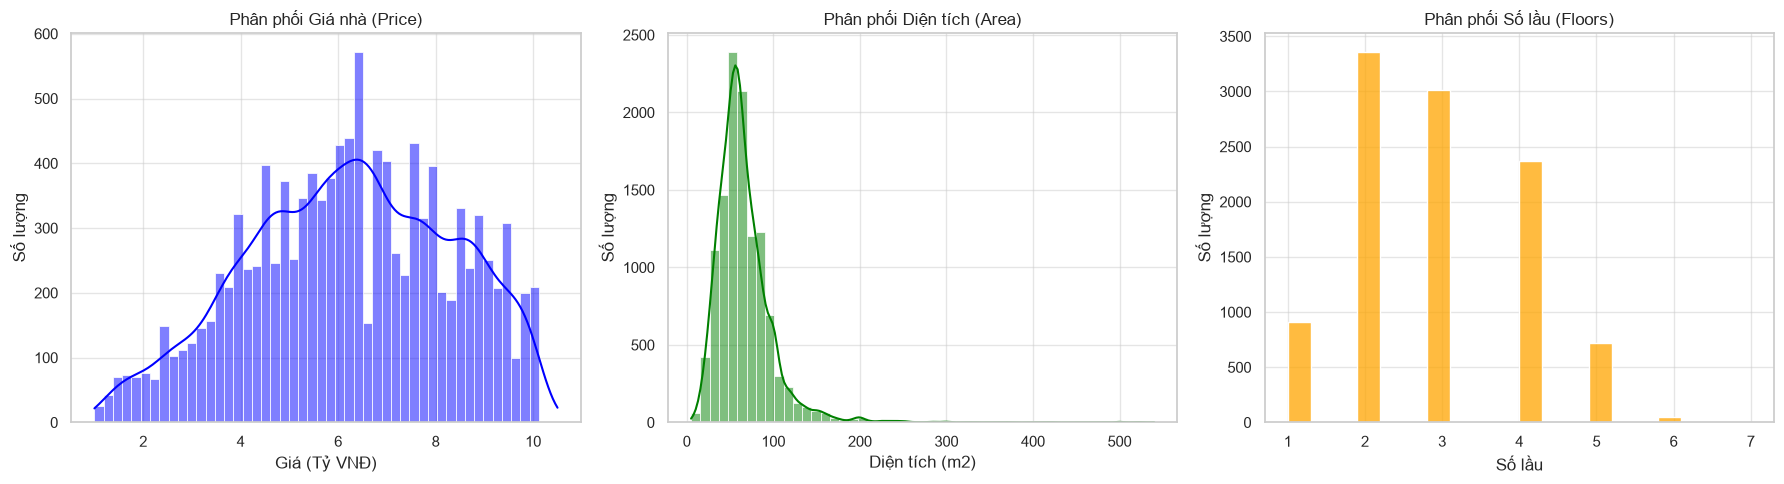

In [2]:
# Tạo khung vẽ gồm 1 hàng, 3 cột
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram cho Giá (Price)
sns.histplot(df['price'], bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Phân phối Giá nhà (Price)')
axes[0].set_xlabel('Giá (Tỷ VNĐ)')
axes[0].set_ylabel('Số lượng')

# 2. Histogram cho Diện tích (Area)
sns.histplot(df['area'], bins=50, kde=True, ax=axes[1], color='green')
axes[1].set_title('Phân phối Diện tích (Area)')
axes[1].set_xlabel('Diện tích (m2)')
axes[1].set_ylabel('Số lượng')

# 3. Histogram cho Số lầu (Floors)
sns.histplot(df['floors'], bins=20, kde=False, ax=axes[2], color='orange')
axes[2].set_title('Phân phối Số lầu (Floors)')
axes[2].set_xlabel('Số lầu')
axes[2].set_ylabel('Số lượng')

plt.tight_layout()
plt.show()

Bảng tỉ lệ thiếu dữ liệu từng cột

In [4]:
# Tính toán số lượng và tỷ lệ % dữ liệu bị khuyết
missing_data = pd.DataFrame(df.isnull().sum(), columns=['Số lượng thiếu'])
missing_data['Tỷ lệ thiếu (%)'] = round((missing_data['Số lượng thiếu'] / len(df)) * 100, 2)

# Sắp xếp giảm dần theo tỷ lệ thiếu
missing_data = missing_data.sort_values(by='Tỷ lệ thiếu (%)', ascending=False)

# In bảng ra màn hình
print("BẢNG THỐNG KÊ TỶ LỆ THIẾU DỮ LIỆU TỪNG CỘT:")
display(missing_data)

BẢNG THỐNG KÊ TỶ LỆ THIẾU DỮ LIỆU TỪNG CỘT:


,Số lượng thiếu,Tỷ lệ thiếu (%)
house_direction,8620,73.19
furniture_state,5664,48.09
frontage,4611,39.15
access_road,4518,38.36
bathrooms,2113,17.94
legal_status,1874,15.91
bedrooms,1598,13.57
floors,1363,11.57
address,0,0.00
area,0,0.00


Boxplot Price theo 25 Quận/Huyện (Sắp theo trung vị)

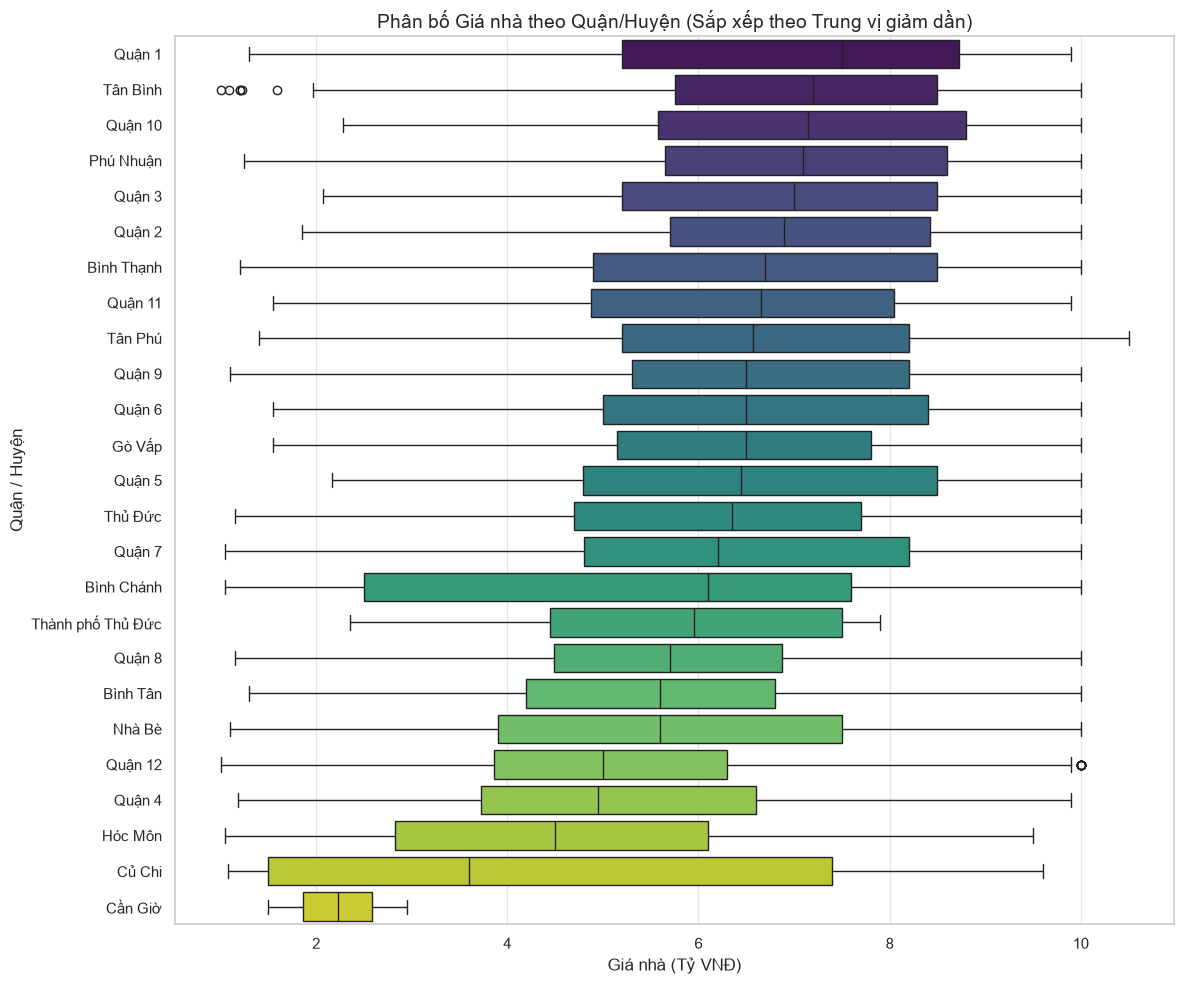

In [5]:
plt.figure(figsize=(12, 10))

# Tính giá trị trung vị (median) của từng quận và sắp xếp giảm dần
order_districts = df.groupby('district')['price'].median().sort_values(ascending=False).index

# Vẽ Boxplot
sns.boxplot(
    data=df,
    x='price',
    y='district',
    order=order_districts,
    palette='viridis'
)

plt.title('Phân bố Giá nhà theo Quận/Huyện (Sắp xếp theo Trung vị giảm dần)', fontsize=14)
plt.xlabel('Giá nhà (Tỷ VNĐ)', fontsize=12)
plt.ylabel('Quận / Huyện', fontsize=12)

# Giới hạn trục X nếu có quá nhiều nhà siêu ngàn tỷ làm hỏng scale biểu đồ (Tùy chỉnh số 50 theo dataset của bạn)
# plt.xlim(0, 50)

plt.tight_layout()
plt.show()


1. **Về phân phối Giá nhà (Price):** Biểu đồ giá nhà có phân phối lệch phải (right-skewed) rất mạnh. Đa số các căn nhà tập trung ở phân khúc dưới [Điền số] tỷ, trong khi xuất hiện một số lượng nhỏ các căn nhà siêu sang (outliers) kéo dài đuôi biểu đồ về bên phải. Điều này cho thấy việc sử dụng Log-transform (np.log1p) trước khi huấn luyện mô hình là hoàn toàn hợp lý.
2. **Về phân phối Diện tích (Area):** Tương tự như giá nhà, diện tích cũng lệch phải. Phần lớn nhà phố tại TP.HCM trong tập dữ liệu có diện tích dao động từ [Điền số] đến [Điền số] m2.
3. **Về mức độ khuyết thiếu dữ liệu:** Các cột đặc trưng như hướng nhà (`house_direction`) hoặc tình trạng nội thất (`furniture_state`) có tỷ lệ thiếu rất cao (lên tới hơn [Điền số]%). Việc drop trực tiếp các cột này sẽ làm mất dữ liệu, do đó chiến lược gom nhóm giá trị thiếu thành nhãn 'Unknown' (như đã làm trong Pipeline) là cần thiết.
4. **Về giá trị bất động sản theo khu vực (Boxplot):** Quận [Điền tên quận đứng đầu, ví dụ: Quận 1, Quận 3] có mức giá trung vị cao nhất, thể hiện rõ đặc thù "tấc đất tấc vàng" ở lõi trung tâm. Các quận vùng ven như [Điền tên quận cuối, ví dụ: Bình Chánh, Củ Chi] có mức giá trung vị thấp nhất và khoảng biến thiên (IQR) hẹp hơn.
5. **Về các điểm dị biệt (Outliers) theo quận:** Nhìn vào biểu đồ Boxplot, hầu hết các quận đều có rất nhiều điểm dị biệt nằm ngoài ria trên (upper whisker). Điều này phản ánh thực tế thị trường bất động sản TP.HCM rất đa dạng; ngay trong một quận bình dân vẫn tồn tại những khu biệt thự hoặc mặt tiền kinh doanh có giá trị đột biến so với mặt bằng chung của quận đó.